In [39]:
from schedule import Schedule, Slot 
from tsn_scheduling_problem import TSNScheduling
from usecase_generator import UsecaseGenerator
from evaluation import GCLDefragmentationEvaluator

In [60]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [41]:
problem = TSNScheduling("uc.config.cfg")

In [42]:
instance = problem.import_scheduling_usecase("instance2.json")

In [43]:
for slot in instance.schedule:
    if slot.start_ns == 29135:
        print(slot.end_ns - slot.start_ns)
        print(slot.duration_ns)

1821.0
1821.0


In [44]:
current = []

slots_to_process = [slot for slot in instance.schedule if slot.stream_id == 0]
slots_to_process.sort(key=lambda slot: slot.start_ns)

# Create individual entries for each slot
for slot in slots_to_process:
    current.append("port: {}, start_time: {}, duration: {}".format(
        slot.port_id, slot.start_ns, slot.duration_ns
    ))

In [45]:
print(current[0])

port: 9, start_time: 49071, duration: 3080.0


In [46]:
with problem.use_instance(instance):
    compact = instance.schedule.to_compact_encoding(problem.n_ports, problem.n_streams)

In [47]:
with problem.use_instance(instance):    
    n_ports = problem.n_ports
    n_streams = problem.n_streams

In [48]:
print(compact[8,0])

49072


In [ ]:
current = []
j = 0  #strem_id
for i in range (0, n_ports):
        if compact[i][j] != 0:
            for slot in instance.schedule:
                if slot.port_id == i+1 and slot.stream_id == j:
                     duration = slot.duration_ns
            current.append({
                "stream" : j,
                "port": i,
                "start_time": int(compact[i][j]),
                "duration": duration
            })
            
current.sort(key=lambda x: x["start_time"])
print(current)


[{'stream': 0, 'port': 8, 'start_time': 49072, 'duration': 3080.0}, {'stream': 0, 'port': 27, 'start_time': 178544, 'duration': 3080.0}, {'stream': 0, 'port': 70, 'start_time': 135447, 'duration': 3080.0}, {'stream': 0, 'port': 73, 'start_time': 92162, 'duration': 3080.0}, {'stream': 0, 'port': 84, 'start_time': 221640, 'duration': 3080.0}, {'stream': 0, 'port': 90, 'start_time': 264736, 'duration': 3080.0}]
[{'stream': 0, 'port': 8, 'start_time': 49072, 'duration': 3080.0}, {'stream': 0, 'port': 73, 'start_time': 92162, 'duration': 3080.0}, {'stream': 0, 'port': 70, 'start_time': 135447, 'duration': 3080.0}, {'stream': 0, 'port': 27, 'start_time': 178544, 'duration': 3080.0}, {'stream': 0, 'port': 84, 'start_time': 221640, 'duration': 3080.0}, {'stream': 0, 'port': 90, 'start_time': 264736, 'duration': 3080.0}]


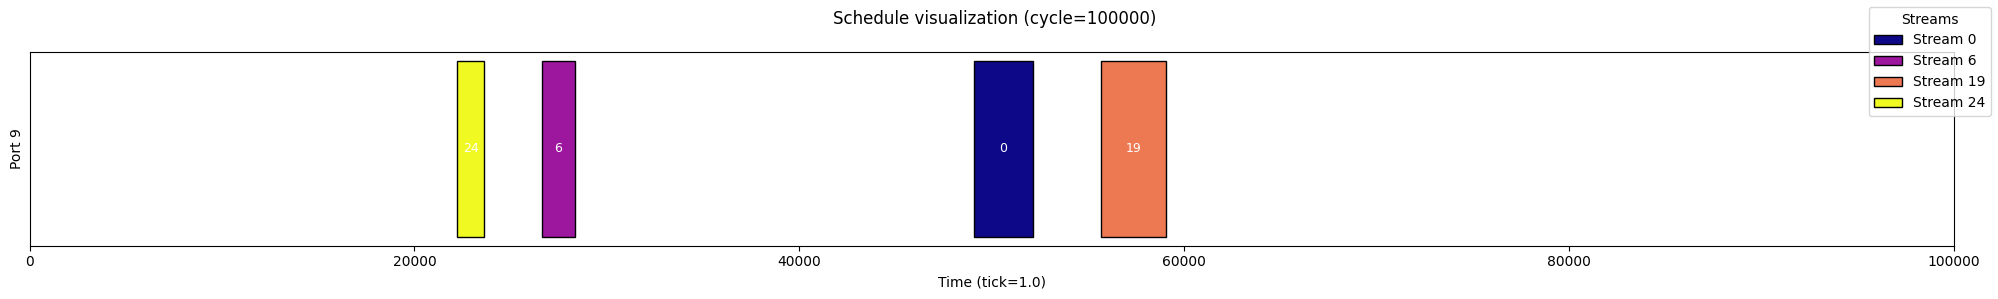

(<Figure size 2000x300 with 1 Axes>,
 [<Axes: xlabel='Time (tick=1.0)', ylabel='Port 9'>])

In [38]:
instance.schedule.plot(port_ids=[9],label=True)

In [84]:
import numpy as np
from tsn_scheduling_problem import TSNScheduling
from heuristic import of_ff_with_current_info

problem = TSNScheduling("uc_config.cfg")
instance = problem.import_scheduling_usecase("instance2.json")

# Higher value = older stream
with problem.use_instance(instance):
    n_streams = problem.n_streams


result, current_info = of_ff_with_current_info(
    problem=problem,
    instance=instance,
    p=10,
    n=5,
)

print("Departed streams:", result.departed_stream_ids)
print("Considered streams:", result.considered_stream_ids)
print("Moved streams:", result.moved_stream_ids)
print(
    "Violation sum before -> after:",
    result.scheduler_violation_sum_before,
    "->",
    result.scheduler_violation_sum_after,
)

if current_info:
    print("\nCurrent info for first considered stream:")
    print(current_info[0])

# Optional: resulting schedules
before_schedule = result.before_schedule
after_schedule = result.after_schedule

Removed stream(s) [28, 10, 27, 8, 13, 7, 24, 1, 14, 6] from schedule successfully.
Departed streams: [28, 10, 27, 8, 13, 7, 24, 1, 14, 6]
Considered streams: [29, 17, 21, 12, 3]
Moved streams: [29, 17, 21, 12, 3]
Violation sum before -> after: 0 -> 0

Current info for first considered stream:
[{'stream': 29, 'port': 4, 'start_time': 27311, 'duration': 1707}, {'stream': 29, 'port': 56, 'start_time': 69028, 'duration': 1707}, {'stream': 29, 'port': 50, 'start_time': 110745, 'duration': 1707}, {'stream': 29, 'port': 18, 'start_time': 152462, 'duration': 1707}, {'stream': 29, 'port': 64, 'start_time': 194179, 'duration': 1707}, {'stream': 29, 'port': 74, 'start_time': 236551, 'duration': 1707}]


In [85]:
# Re-run your existing cell, then inspect debug details like this:

for r in result.debug_reports:
    print("\n--- stream", r["stream"], "---")
    print("baseline_violation_sum:", r["baseline_violation_sum"])
    print("candidate_violation_sum:", r["candidate_violation_sum"])
    print("accepted:", r["accepted"], "| reason:", r["reason"])

    print("port_attempts:")
    for p in r["port_attempts"]:
        print(
            "  port={port}, current={current_start}, first_fit={first_fit_start}, had_earlier_hole={had_earlier_hole}".format(
                **p
            )
        )

    print("per_check_violation_deltas:")
    for k, v in r["per_check_violation_deltas"].items():
        print(f"  {k}: {v}")


--- stream 29 ---
baseline_violation_sum: 0
candidate_violation_sum: 0
accepted: True | reason: accepted
port_attempts:
  port=4, current=27311, first_fit=0, had_earlier_hole=True
  port=56, current=69028, first_fit=69028, had_earlier_hole=False
  port=50, current=110745, first_fit=70785, had_earlier_hole=True
  port=18, current=152462, first_fit=152462, had_earlier_hole=False
  port=64, current=194179, first_fit=194179, had_earlier_hole=False
  port=74, current=236551, first_fit=236551, had_earlier_hole=False
per_check_violation_deltas:
  stream_window_sequence: 0
  interleaving: 0
  macrocycle_overlap: 0
  talker_offset: 0
  maxlatency_violations: 0

--- stream 17 ---
baseline_violation_sum: 0
candidate_violation_sum: 0
accepted: True | reason: accepted
port_attempts:
  port=14, current=28428, first_fit=0, had_earlier_hole=True
  port=93, current=70218, first_fit=1827, had_earlier_hole=True
  port=86, current=112005, first_fit=3654, had_earlier_hole=True
  port=25, current=153792, f

In [70]:
result, current_info = of_ff_with_current_info(
    problem=problem,
    instance=instance,
    p=5,
    n=1,
)

Removed stream(s) [28, 10, 27, 8, 13] from schedule successfully.


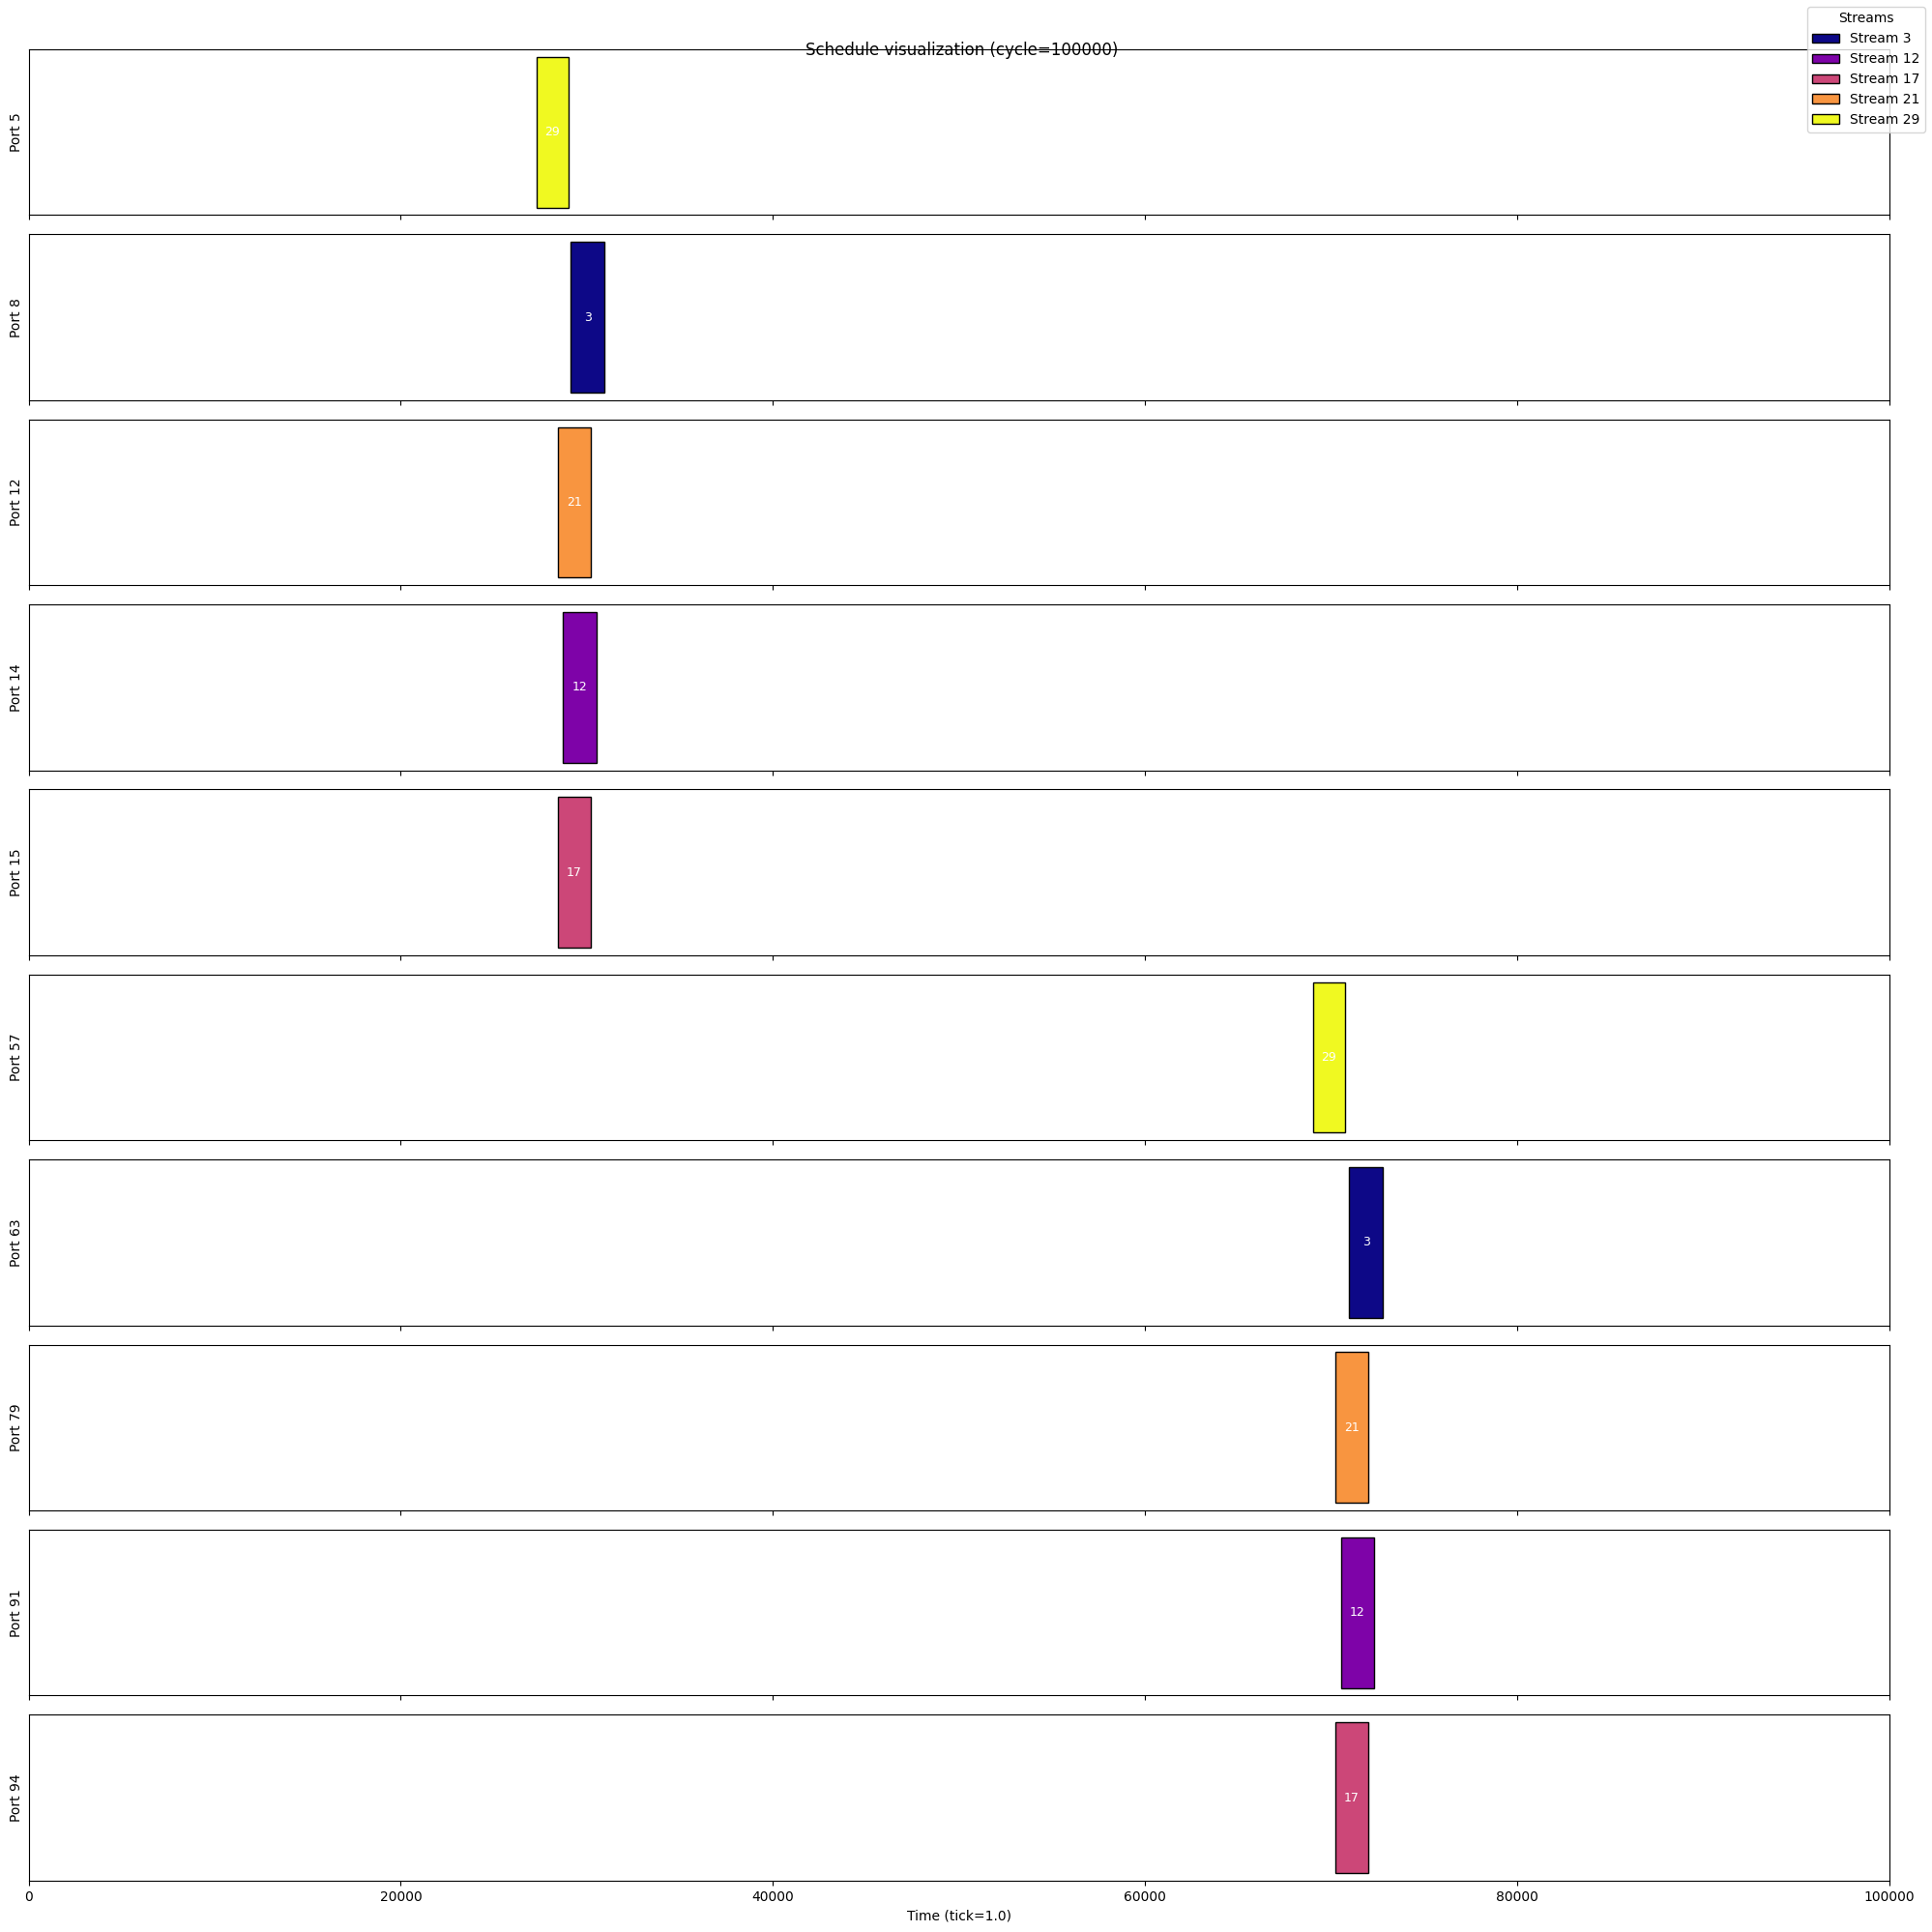

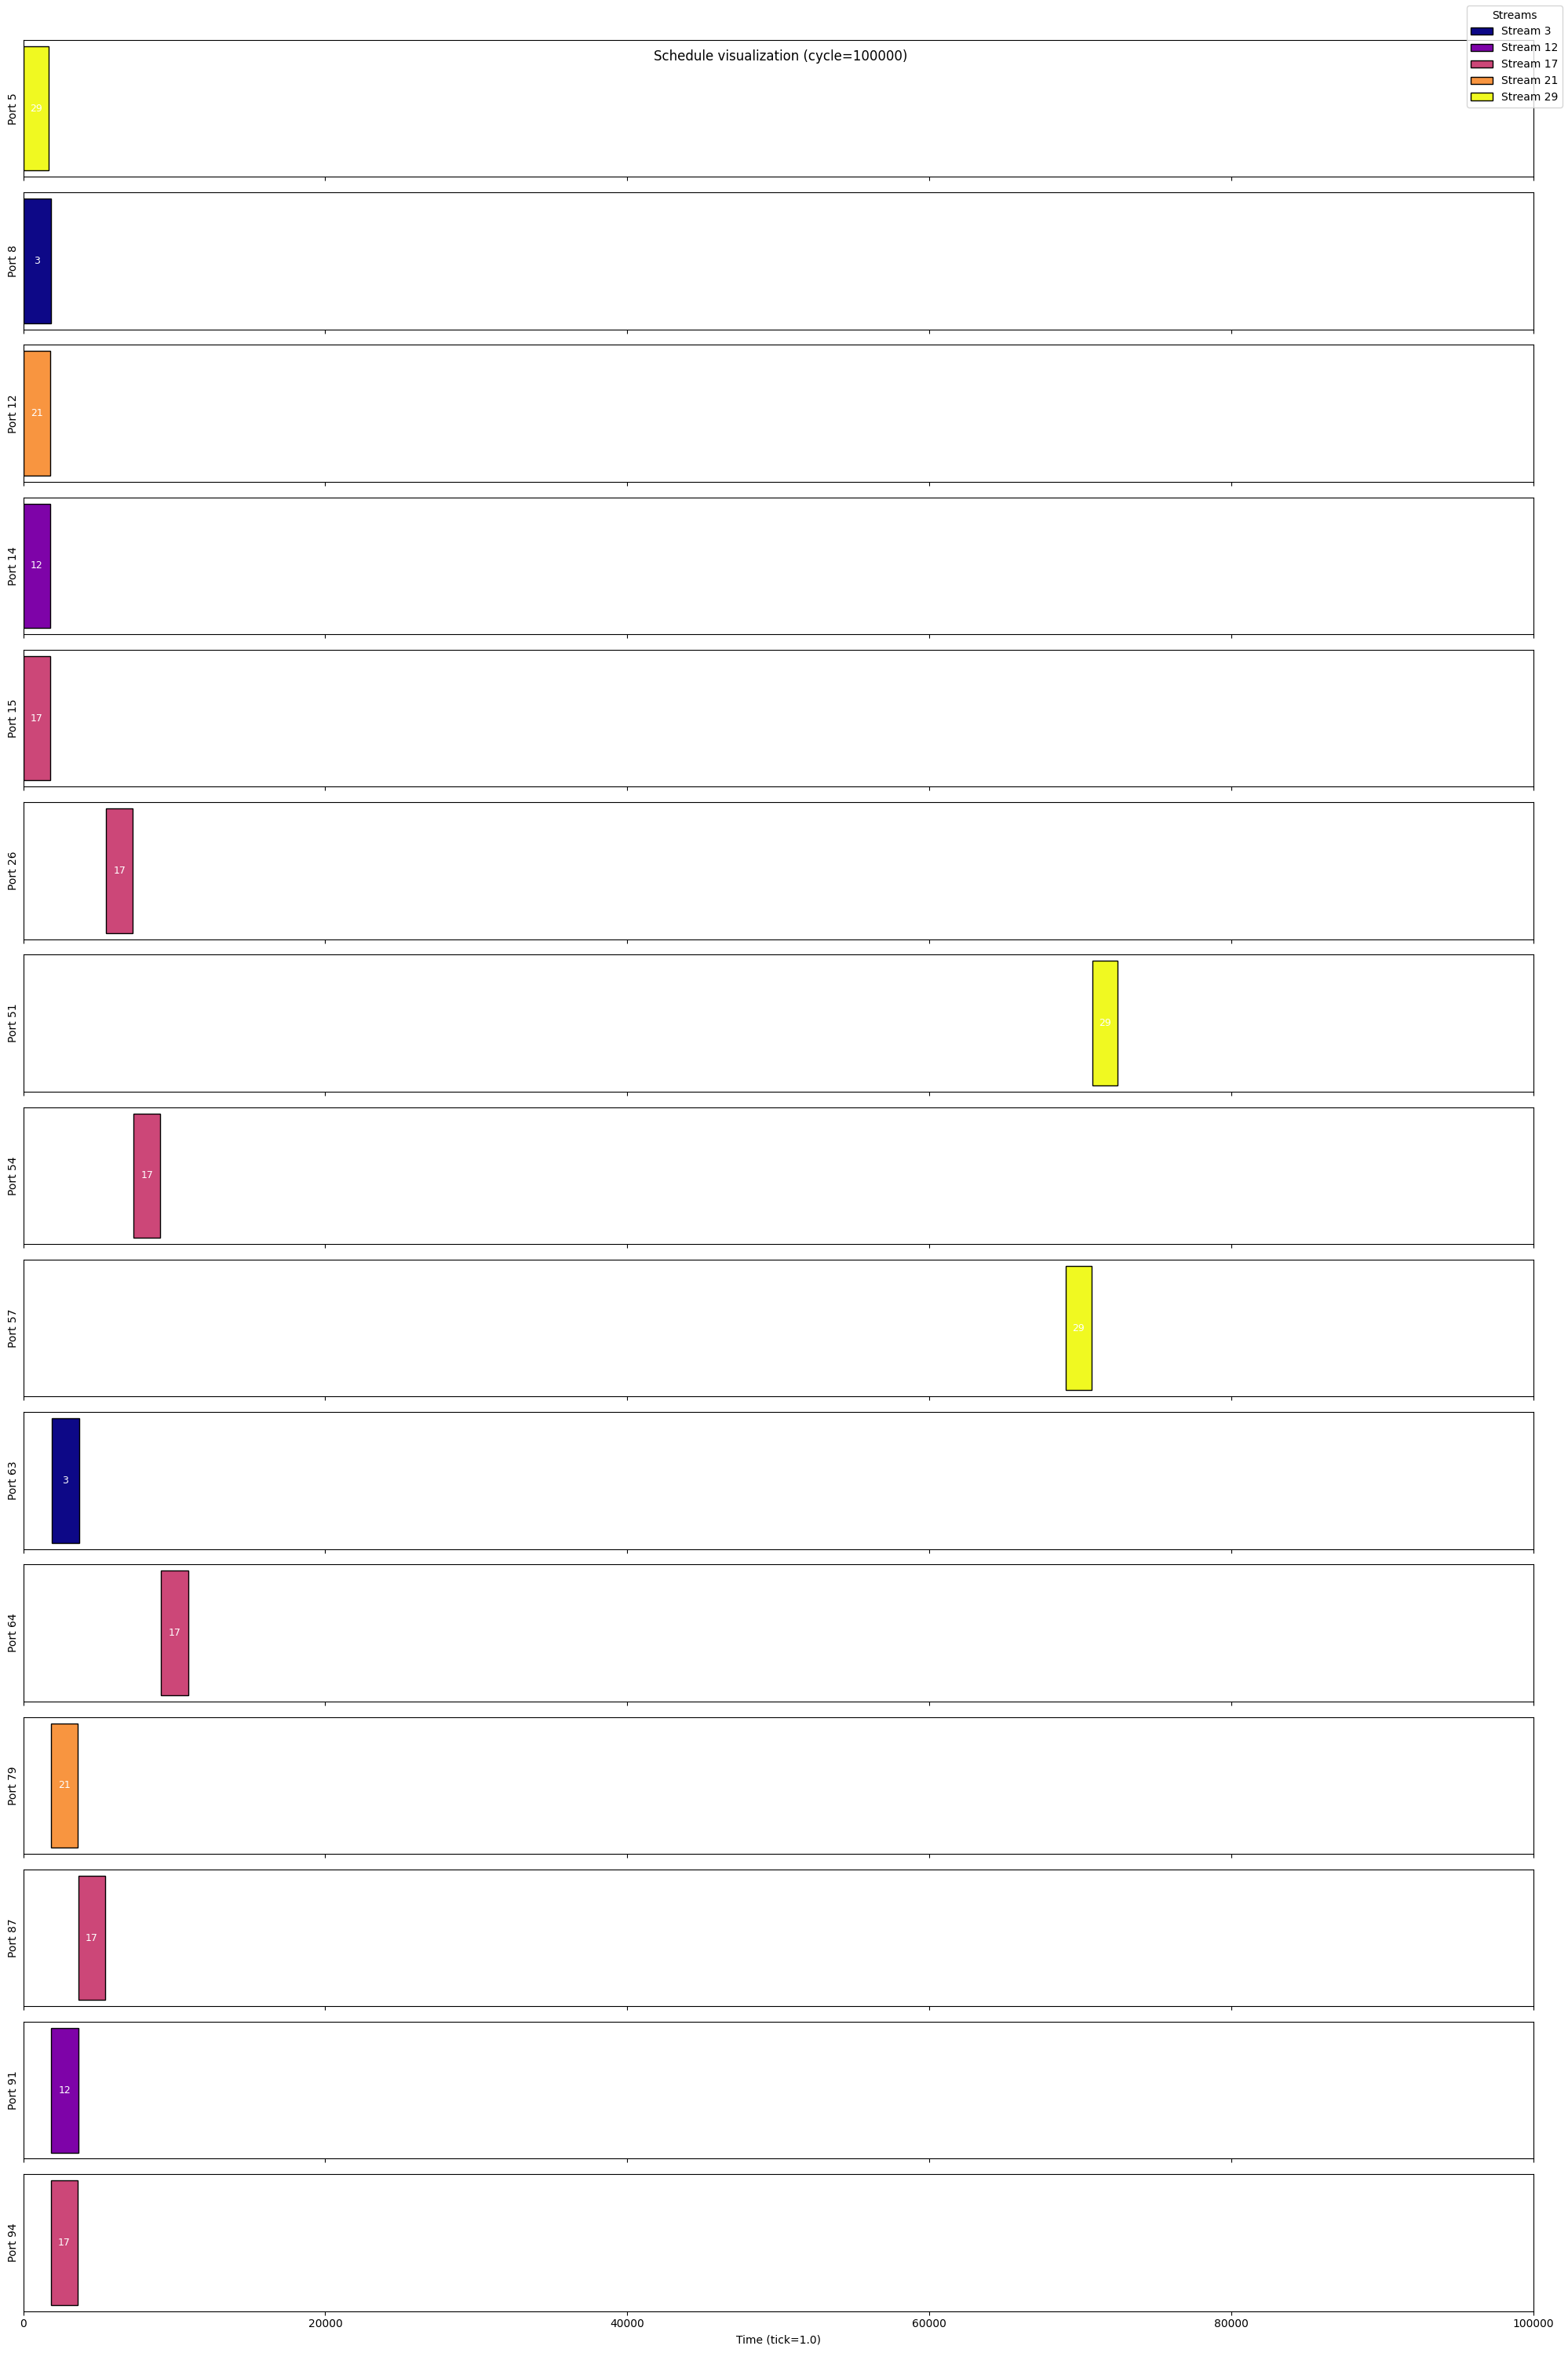

(<Figure size 2000x3000 with 15 Axes>,
 array([<Axes: ylabel='Port 5'>, <Axes: ylabel='Port 8'>,
        <Axes: ylabel='Port 12'>, <Axes: ylabel='Port 14'>,
        <Axes: ylabel='Port 15'>, <Axes: ylabel='Port 26'>,
        <Axes: ylabel='Port 51'>, <Axes: ylabel='Port 54'>,
        <Axes: ylabel='Port 57'>, <Axes: ylabel='Port 63'>,
        <Axes: ylabel='Port 64'>, <Axes: ylabel='Port 79'>,
        <Axes: ylabel='Port 87'>, <Axes: ylabel='Port 91'>,
        <Axes: xlabel='Time (tick=1.0)', ylabel='Port 94'>], dtype=object))

In [86]:
result.before_schedule.plot(label=True,stream_ids=[29,17,21,12,3])
result.after_schedule.plot(label=True,stream_ids=[29,17,21,12,3])

In [80]:
for r in result.debug_reports:
    for p in r["port_attempts"]:
        print(
            "port", p["port"],
            "current", p["current_start"],
            "lb", p.get("lower_bound"),
            "first_fit", p["first_fit_start"],
            "checked", p.get("checked_candidates", [])
        )

port 3 current 20308 lb 0 first_fit 0 checked [0]
port 46 current 62585 lb 41338 first_fit 41338 checked [41338]


In [87]:
from heuristic import of_ff_with_current_info, print_run_summary

result, current_info = of_ff_with_current_info(
    problem=problem,
    instance=instance,
    p=10,
    n=5,
)

print_run_summary(result)

Removed stream(s) [28, 10, 27, 8, 13, 7, 24, 1, 14, 6] from schedule successfully.
=== OF-FF Summary ===
Departed streams: [28, 10, 27, 8, 13, 7, 24, 1, 14, 6]
Considered streams: [29, 17, 21, 12, 3]
Moved streams: [29, 17, 21, 12, 3]
Violation sum before -> after: 0 -> 0
Largest hole mean before -> after: 88231.15625 -> 92811.14583333333 (delta: 4579.9895833333285 )
Largest hole max before -> after: 100000 -> 100000 (delta: 0.0 )

Holes >= c (before -> after):
  c=500: 151 -> 130
  c=1000: 151 -> 130
  c=2000: 149 -> 125
  c=5000: 141 -> 119

C-capacity total (before -> after):
  c=500: 18936 -> 18985
  c=1000: 9448 -> 9477
  c=2000: 4704 -> 4722
  c=5000: 1856 -> 1872
